## EMERGENT Analysis: Notebook 2
#### Relationship between PANSS scores and DHMs

### 1 - Setup

Load necessary packages, define relevant paths for data and storing figures.

In [1]:
%load_ext rpy2.ipython

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from tqdm import tqdm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from matplotlib.patches import Patch
from sklearn.metrics import mean_squared_error, r2_score 
from scipy.stats import pearsonr

import sys
sys.path.append('/home/ssm-user/bklynhlth-science/common_functions/')
from analysis import (
    scatterplot, boxplot_ttest, distribution,
    calculate_labelpad_and_left, mlr_test, cohens_d, lme_test,
    train_and_test, plot_feature_importance, scatterplot_rmse,
    train_rf_model, test_rf_model, boxplot_sites_multiple,
    boxplot_anova, distribution_grid, boxplot_sites, boxplot_sites_adj, 
    tukey_anova, boxplot_visits, boxplot_visits_multiple, boxplot_sites
)
from study_data import remove_outliers

pd.set_option('display.max_rows', None)
warnings.simplefilter(action='ignore', category=FutureWarning)

from rpy2.robjects import pandas2ri
import rpy2.robjects as ro
from rpy2.robjects.conversion import localconverter

# Activate pandas2ri to convert pandas dataframe into R dataframes
#pandas2ri.activate()

#warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
%%R
library(lmerTest)
library(effectsize) # for partial eta2 values
library(performance) # for Nakagawa conditional/marginal R2

lme_test <- function(df_temp, dep_var, ind_vars, random_effects, print_stats=FALSE, fit_reduced=FALSE) {
  # Construct the formula for the full model
  fixed_effects <- paste(c(ind_vars, random_effects[2]), collapse = " + ")
  formula_full <- as.formula(paste(dep_var, "~", fixed_effects, "+ (", random_effects[2],"|", random_effects[1], ")"))
    
  # Fit the full model
  model_full <- lmerTest::lmer(formula_full, data = df_temp)
  
  # Get results for the variable of interest
  summary_full <- summary(model_full)
  pval <- summary_full$coefficients[ind_vars[1], "Pr(>|t|)"]
  coef <- summary_full$coefficients[ind_vars[1], "Estimate"]
  conf_int <- confint(model_full, parm = ind_vars[1], level = 0.95)
  
  if (print_stats) {
    print(summary_full)
  }
  
  if (!fit_reduced) {
    return(list(pval = pval, coef = coef, partial_r2 = NULL, part_r2 = NULL, conf_int = conf_int))
  }

  # Construct the formula for the reduced model (excluding the first independent variable)
  fixed_effects_reduced <- paste(c(ind_vars[-1], random_effects[2]), collapse = " + ")
  formula_reduced <- as.formula(paste(dep_var, "~", fixed_effects_reduced, "+ (", random_effects[2],"|", random_effects[1], ")"))
  
  # Fit the reduced model
  model_reduced <- lmer(formula_reduced, data = df_temp)
  
  # Calculate marginal R-squared for full and reduced models
  r2_full <- r2_nakagawa(model_full)
  r2_reduced <- r2_nakagawa(model_reduced)
  full_marginal_r2 <- r2_full$R2_marginal
  reduced_marginal_r2 <- r2_reduced$R2_marginal
  
  # Partial R2 calculation
  partial_r2 <- (full_marginal_r2 - reduced_marginal_r2) / (1 - reduced_marginal_r2)
   
  # Partial eta2 calculation
  eta_sq_results <- eta_squared(model_full, partial = TRUE)

  return(list(pval = pval, coef = coef, partial_r2 = as.numeric(partial_r2), part_r2 = NULL, partial_eta2 = as.numeric(eta_sq_results$Eta2_partial[1]), conf_int = conf_int))
}

step_forward_selection <- function(df_temp, dep_var, initial_vars, ind_vars, random_effects) {
  selected_vars <- initial_vars
  remaining_vars <- ind_vars
  best_model <- NULL
  best_pval <- 1
  alpha <- 0.05
  n_tests <- length(ind_vars)
    
  vars <- c()
  stats <- c()
  
  while (length(remaining_vars) > 0) {
    pval_values <- sapply(remaining_vars, function(var) {
      current_vars <- c(selected_vars, var)
      fixed_effects <- paste(c(current_vars, random_effects[2]), collapse = " + ")
      formula_current <- as.formula(paste(dep_var, "~", fixed_effects, "+ (", random_effects[2], "|", random_effects[1], ")"))
      model_current <- lmer(formula_current, data = df_temp)
      summary_current <- summary(model_current)
      return(summary_current$coefficients[var, "Pr(>|t|)"])
    })
    
    best_var <- remaining_vars[which.min(pval_values)]
    best_var_pval <- min(pval_values)
    
    if (best_var_pval < (alpha / n_tests)) {
      res <- lme_test(df_temp, dep_var, c(best_var, selected_vars), random_effects, fit_reduced=TRUE)
      stats <- rbind(stats, c(res$partial_r2, res$partial_eta2))
      vars <- c(vars, best_var)
        
      best_pval <- best_var_pval
      selected_vars <- c(selected_vars, best_var)
      remaining_vars <- setdiff(remaining_vars, best_var)
      fixed_effects <- paste(c(selected_vars, random_effects[2]), collapse = " + ")
      formula_best <- as.formula(paste(dep_var, "~", fixed_effects, "+ (", random_effects[2], "|", random_effects[1], ")"))
      best_model <- lmer(formula_best, data = df_temp)
      n_tests <- length(remaining_vars)
      
    } else {
      break
    }
  }
  
  return(list(best_model = best_model, vars = vars, stats = stats))
}

Loading required package: lme4
Loading required package: Matrix

Attaching package: ‘lmerTest’

The following object is masked from ‘package:lme4’:

    lmer

The following object is masked from ‘package:stats’:

    step



In [4]:
figure_dir = '/home/ssm-user/bklynhlth-science/michelleworthington/emergent_analysis/figures/final_figures/notebook2_PANSS/'

#### 1.1 - Load data

Load compiled data from first notebook.

In [5]:
df = pd.read_csv('/home/ssm-user/bklynhlth-science/datasets/datasets_engagements/emergent/emergent_analysis_df.csv')

In [6]:
# define DHMs
dhms = ['file_length', 'speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean', 'word_pause_variability',
       'mean_pre_turn_pause', 'positive_sentiment', 'negative_sentiment',
       'lexical_richness',
       'first_person_percentage',
       'first_person_sentiment_positive', 'first_person_sentiment_negative',
       'first_person_sentiment_overall', 'word_repeat_percentage',
       'phrase_repeat_percentage',
       'word_coherence_mean', 'word_coherence_var', 'word_coherence_5_mean',
       'word_coherence_5_var', 'word_coherence_10_mean',
       'word_coherence_10_var', 'word_coherence_variability_2_mean',
       'word_coherence_variability_2_var', 'word_coherence_variability_3_mean',
       'word_coherence_variability_3_var', 'word_coherence_variability_4_mean',
       'word_coherence_variability_4_var', 'word_coherence_variability_5_mean',
       'word_coherence_variability_5_var', 'word_coherence_variability_6_mean',
       'word_coherence_variability_6_var', 'word_coherence_variability_7_mean',
       'word_coherence_variability_7_var', 'word_coherence_variability_8_mean',
       'word_coherence_variability_8_var', 'word_coherence_variability_9_mean',
       'word_coherence_variability_9_var',
       'word_coherence_variability_10_mean',
       'word_coherence_variability_10_var',
       'first_order_sentence_tangeniality_mean',
       'first_order_sentence_tangeniality_var',
       'second_order_sentence_tangeniality_mean',
       'second_order_sentence_tangeniality_var',
       'turn_to_turn_tangeniality_mean', 'turn_to_turn_tangeniality_var',
       'turn_to_turn_tangeniality_slope', 'semantic_perplexity_mean',
       'semantic_perplexity_var', 'f0_mean', 'f0_stddev', 'f1_mean', 'f1_stddev', 
       'f2_mean', 'f2_stddev', 'f3_mean', 'f3_stddev', 'f4_mean', 'f4_stddev',
       'loudness_mean', 'loudness_stddev', 'hnr_mean',
       'hnr_stddev', 'jitter', 'jitter_abs',
       'jitter_rap', 'jitter_ppq5', 'jitter_ddp', 'shimmer', 'shimmer_db',
       'shimmer_apq3', 'shimmer_apq5', 'shimmer_apq11', 'shimmer_dda',
       'gne_ratio', 'silence_ratio']

In [7]:
# adjust Speech Length In Minutes, Speech Length In Words

df['speech_length_in_minutes_adjusted'] = df['speech_length_in_minutes'] / df['file_length']
df['speech_length_in_words_adjusted'] = df['speech_length_in_words'] / df['file_length']

In [8]:
# creating a dataframe that has data from screening only

df_screening = df[df['visit'] == 1].drop_duplicates(subset='id', keep='first')

In [9]:
df_clean = remove_outliers(df.copy(), dhms)
df_screening_clean = remove_outliers(df_screening.copy(), dhms)

### 2 - DHMs vs. PANSS

#### 2.1 - Summary tables

With correlations from pooled visits:

In [11]:
dep_vars = ['panss_ptot', 'panss_ntot']
display_names = {
    'panss_ptot': 'PANSS-P',
    'panss_ntot': 'PANSS-N',
}
 
df2 = df_clean.copy()
 
corr_results = {dv: [] for dv in dep_vars}
for dep_var in dep_vars:
    for dhm in dhms:
        valid = df2[[dhm, dep_var]].dropna()
        try:
            r, p = stats.pearsonr(valid[dhm], valid[dep_var])
        except Exception:
            r, p = np.nan, np.nan
        corr_results[dep_var].append({'dhm': dhm, 'n': len(valid), 'r': r, 'pval': p})
 
corr_table = pd.DataFrame({'DHM': [d.replace('_', ' ').title() for d in dhms]})
for dep_var in dep_vars:
    df_dv = pd.DataFrame(corr_results[dep_var])
    label = display_names[dep_var]
    corr_table[f'{label} (n)'] = df_dv['n']
    corr_table[f'{label} (r)'] = df_dv['r'].round(3)
    corr_table[f'{label} (pval)'] = df_dv['pval'].round(3)
 
corr_table.to_csv('speech_panss_correlations.csv', index=False)
corr_table

,DHM,PANSS-P (n),PANSS-P (r),PANSS-P (pval),PANSS-N (n),PANSS-N (r),PANSS-N (pval)
0,File Length,3391,0.462,0.000,3391,-0.025,0.151
1,Speech Length In Minutes Adjusted,3479,0.267,0.000,3479,-0.187,0.000
2,Speech Length In Words Adjusted,3423,0.253,0.000,3423,-0.223,0.000
3,Mean Turn Length In Minutes,3328,0.243,0.000,3328,-0.160,0.000
4,Mean Turn Length In Words,3307,0.247,0.000,3307,-0.214,0.000
5,Speaker Percentage,3444,0.280,0.000,3444,-0.235,0.000
6,Words Per Minute,3450,0.147,0.000,3450,-0.198,0.000
7,Syllables Per Minute,3454,0.152,0.000,3454,-0.203,0.000
8,Word Pause Length Mean,3320,-0.157,0.000,3320,0.224,0.000
9,Word Pause Variability,3203,-0.130,0.000,3203,0.195,0.000


For just KAR-004:

In [12]:
df_clean['study'].value_counts()

study
kar007    1553
kar009    1512
kar004     882
Name: count, dtype: int64

In [13]:
kar004 = df_clean[df_clean['study'] == 'kar004']

In [14]:
dep_vars = ['panss_ptot', 'panss_ntot']
display_names = {
    'panss_ptot': 'PANSS-P',
    'panss_ntot': 'PANSS-N',
}
 
df3 = kar004.copy()
 
corr_results = {dv: [] for dv in dep_vars}
for dep_var in dep_vars:
    for dhm in dhms:
        valid = kar004[[dhm, dep_var]].dropna()
        try:
            r, p = stats.pearsonr(valid[dhm], valid[dep_var])
        except Exception:
            r, p = np.nan, np.nan
        corr_results[dep_var].append({'dhm': dhm, 'n': len(valid), 'r': r, 'pval': p})
 
corr_table_kar004 = pd.DataFrame({'DHM': [d.replace('_', ' ').title() for d in dhms]})
for dep_var in dep_vars:
    df_dv = pd.DataFrame(corr_results[dep_var])
    label = display_names[dep_var]
    corr_table[f'{label} (n)'] = df_dv['n']
    corr_table[f'{label} (r)'] = df_dv['r'].round(3)
    corr_table[f'{label} (pval)'] = df_dv['pval'].round(3)
 
corr_table_kar004.to_csv('speech_panss_correlations_kar004.csv', index=False)
corr_table

,DHM,PANSS-P (n),PANSS-P (r),PANSS-P (pval),PANSS-N (n),PANSS-N (r),PANSS-N (pval)
0,File Length,794,0.346,0.000,794,-0.116,0.001
1,Speech Length In Minutes Adjusted,825,0.275,0.000,825,-0.223,0.000
2,Speech Length In Words Adjusted,801,0.291,0.000,801,-0.242,0.000
3,Mean Turn Length In Minutes,782,0.197,0.000,782,-0.232,0.000
4,Mean Turn Length In Words,774,0.234,0.000,774,-0.272,0.000
5,Speaker Percentage,809,0.295,0.000,809,-0.258,0.000
6,Words Per Minute,814,0.237,0.000,814,-0.218,0.000
7,Syllables Per Minute,816,0.238,0.000,816,-0.241,0.000
8,Word Pause Length Mean,791,-0.184,0.000,791,0.297,0.000
9,Word Pause Variability,760,-0.150,0.000,760,0.226,0.000


Without correlations, LME only:

In [18]:
summaries = {'panss_ptot': [], 'panss_ntot': [], 'panss_gtot': [], 'panss': []}

r_code = """
result <- lme_test(df_plot, dv, fefs, refs, FALSE, TRUE)
"""

df2 = df_clean.copy()
for dep_var in tqdm(summaries.keys(), desc=f"Dependent Variables"):
    for dhm in tqdm(dhms, desc=f"DHMs ({dep_var})"):
        df_plot = df2.dropna(
            subset=['id', dep_var] + [dhm, 'age', 'male', 'black', 'visit']
        ).copy()

        # run model
        try:
            with localconverter(ro.default_converter + pandas2ri.converter):
                r_df_plot = ro.conversion.py2rpy(df_plot)

            # Assign the dataframe and variables to R
            ro.globalenv['df_plot'] = r_df_plot
            ro.globalenv['dv'] = dep_var
            ro.globalenv['fefs'] = ro.StrVector([dhm, 'age', 'male', 'black'])
            ro.globalenv['refs'] = ro.StrVector(['id', 'visit'])

            ro.r(r_code)
            result = ro.globalenv['result']
            result_dict = dict(zip([str(x) for x in result.names], list(result)))
            
            pval = result_dict['pval'][0]
            coef = result_dict['coef'][0]
            ci = result_dict['conf_int'][0]
            partial_r2 = result_dict['partial_r2'][0]
#             part_r2 = result_dict['part_r2'][0]
            partial_eta2 = result_dict['partial_eta2'][0]

        except:
            pval = 1
            coef = 1

        if pval < 1: # change to < 1 for reporting all stats in ms and posters
            res = []
            if coef > 0:
                res.append('+')
            else:
                res.append('-')

            res.append(f'{np.round(coef, 3)} ({np.round(ci[0], 3)}, {np.round(ci[1], 3)})')
            res.append(f'{np.round(partial_r2, 3)}')
#             res.append(f'{np.round(part_r2, 3)}')
            res.append(f'{np.round(partial_eta2, 3)}')
            res.append(f'{np.round(pval, 3)}')

            summaries[dep_var].append(res)
        else:
            summaries[dep_var].append(['' for _ in range(5)])

DHMs (panss_ptot):   0%|                                 | 0/80 [00:00<?, ?it/s]R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: Warning messages:

R[write to console]: 1: 
R[write to console]: In checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv,  :
R[write to console]: 
 
R[write to console]:  Model failed to converge with max|grad| = 0.00326302 (tol = 0.002, component 1)

R[write to console]: 2: 
R[write to console]: In checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv,  :
R[write to console]: 
 
R[write to console]:  Model failed to converge with max|grad| = 0.00200802 (tol = 0.002, component 1)


DHMs (panss_ptot):   1%|▎                        | 1/80 [00:04<05:43,  4.35s/it]R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: Warning message:

R[write to console]: In checkConv(attr(opt, "derivs"), opt$par, ctrl =

In [19]:
summary_data = {
    'DHM': [item.replace('_', ' ').title() for item in dhms],
    'PANSS-P': [x[0] for x in summaries['panss_ptot']],
    'PANSS-N': [x[0] for x in summaries['panss_ntot']],
    'PANSS-G': [x[0] for x in summaries['panss_gtot']],
    'PANSS': [x[0] for x in summaries['panss']]
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,PANSS-P,PANSS-N,PANSS-G,PANSS
0,File Length,+,-,+,+
1,Speech Length In Minutes Adjusted,+,-,+,+
2,Speech Length In Words Adjusted,+,-,+,+
3,Mean Turn Length In Minutes,+,-,+,+
4,Mean Turn Length In Words,+,-,+,+
5,Speaker Percentage,+,-,+,+
6,Words Per Minute,+,-,+,-
7,Syllables Per Minute,+,-,+,-
8,Word Pause Length Mean,-,+,+,+
9,Word Pause Variability,-,+,+,+


#### 2.3 - PANSS feature importances

In [17]:
df2 = df_clean.copy()
df2 = df2.dropna(
    subset=['id', 'panss_ptot', 'panss_ntot', 'age', 'male', 'black', 'visit'] + dhms
).copy()

with localconverter(ro.default_converter + pandas2ri.converter):
    r_df2 = ro.conversion.py2rpy(df2)
    
r_code = "result <- step_forward_selection(df2, dv, initial, candidates, random_efs)"

In [18]:
# PANSS Positive
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'panss_ptot'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_efs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_positive = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [19]:
# PANSS Negative
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'panss_ntot'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_efs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_negative = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [20]:
# PANSS General
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'panss_gtot'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_efs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_general = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [21]:
# PANSS Overall
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'panss'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_efs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_overall = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [22]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_positive[0]],
    'PANSS-P (partial R^2)': [x[0] for x in var_contributions_positive[1]],
    'PANSS-P (partial eta^2)': [x[1] for x in var_contributions_positive[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,PANSS-P (partial R^2),PANSS-P (partial eta^2)
0,Lexical Richness,0.039722,0.081459
1,Turn To Turn Tangeniality Mean,0.011796,0.018649
2,Word Coherence Mean,0.009511,0.017701
3,Negative Sentiment,0.009950,0.016897


In [23]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_negative[0]],
    'PANSS-N (partial R^2)': [x[0] for x in var_contributions_negative[1]],
    'PANSS-N (partial eta^2)': [x[1] for x in var_contributions_negative[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,PANSS-N (partial R^2),PANSS-N (partial eta^2)
0,Speaker Percentage,0.057522,0.064852
1,Negative Sentiment,0.011977,0.019377
2,Mean Pre Turn Pause,0.015904,0.017110


In [24]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_general[0]],
    'PANSS-G (partial R^2)': [x[0] for x in var_contributions_general[1]],
    'PANSS-G (partial eta^2)': [x[1] for x in var_contributions_general[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,PANSS-G (partial R^2),PANSS-G (partial eta^2)
0,Lexical Richness,0.020629,0.039325
1,Mean Pre Turn Pause,0.034577,0.036977
2,Negative Sentiment,0.025906,0.036905


In [25]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_overall[0]],
    'PANSS (partial R^2)': [x[0] for x in var_contributions_overall[1]],
    'PANSS (partial eta^2)': [x[1] for x in var_contributions_overall[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,PANSS (partial R^2),PANSS (partial eta^2)
0,Negative Sentiment,0.017499,0.035721
1,Mean Pre Turn Pause,0.026954,0.036436
2,Lexical Richness,0.025414,0.045980


### 3 - DHMs vs. Marder Factor scores

#### 3.1 - Relationships

##### 3.1.1 - Marder positive symptoms 

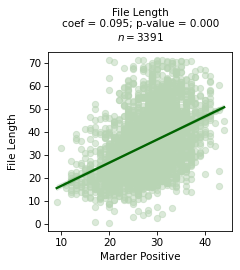

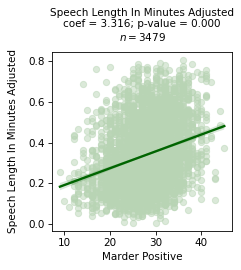

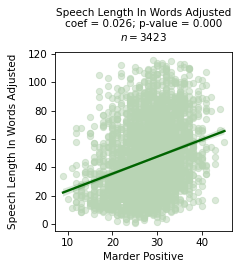

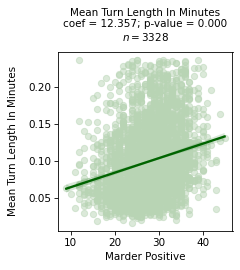

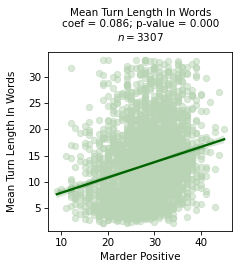

...

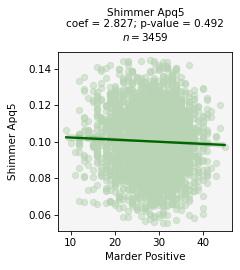

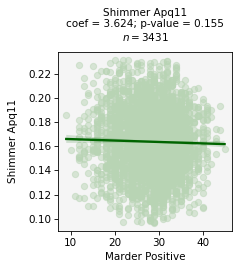

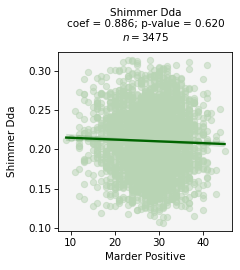

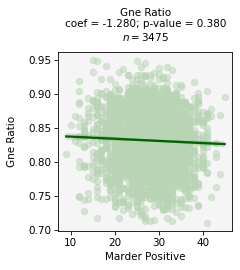

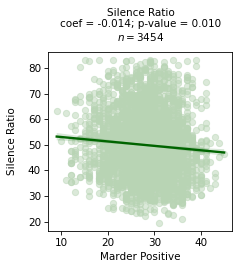

In [26]:
# Linear mixed effect model, with timepoint as a factor
for dhm in dhms:
    scatterplot(df_clean, 'marder_positive', [dhm, 'age', 'male', 'black'], 'Marder Positive', dhm.replace("_", " ").title(), None, 0.05, 'lme', dpi=200, filename=figure_dir+f"3.1.1_scatterplot_lme_marder-positive_{dhm}.png")
    scatterplot(df_clean, 'marder_positive', [dhm, 'age', 'male', 'black'], 'Marder Positive', dhm.replace("_", " ").title(), None, 1, 'lme', dpi=75)

##### 3.1.2 - Marder negative symptoms

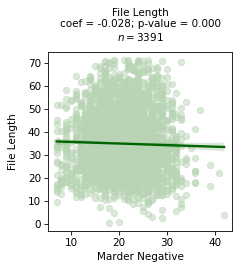

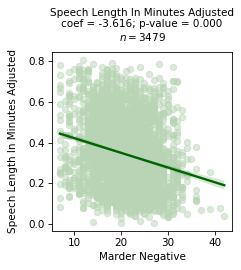

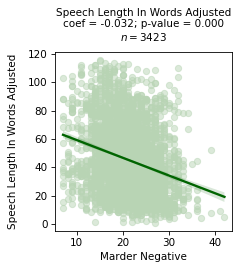

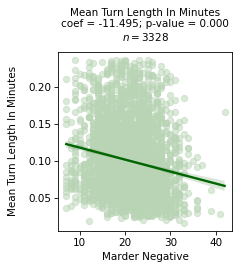

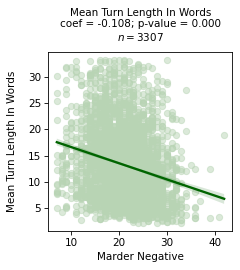

...

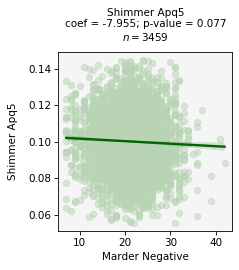

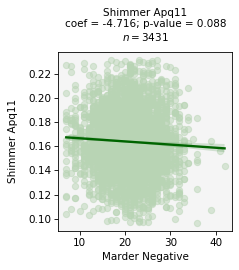

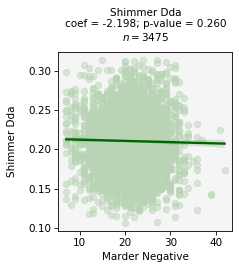

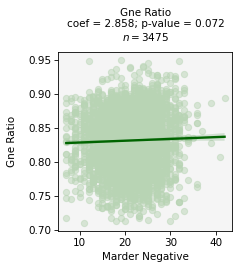

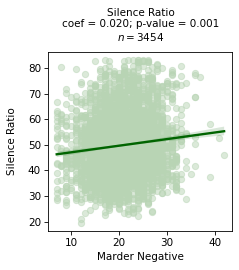

In [27]:
# Linear mixed effect model, with timepoint as a factor
for dhm in dhms:
    scatterplot(df_clean, 'marder_negative', [dhm, 'age', 'male', 'black'], 'Marder Negative', dhm.replace("_", " ").title(), None, 0.05, 'lme', dpi=200, filename=figure_dir+f"3.1.2_scatterplot_lme_marder-negative_{dhm}.png")
    scatterplot(df_clean, 'marder_negative', [dhm, 'age', 'male', 'black'], 'Marder Negative', dhm.replace("_", " ").title(), None, 1, 'lme', dpi=75)

##### 3.1.3 - Marder disorganized thought

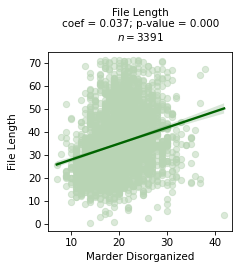

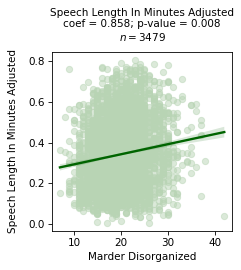

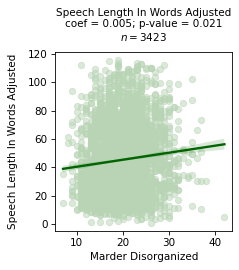

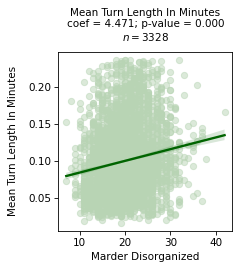

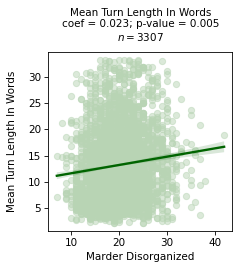

...

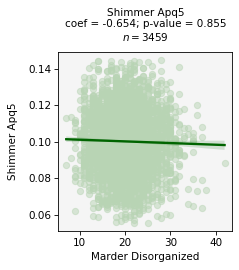

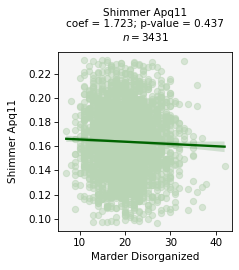

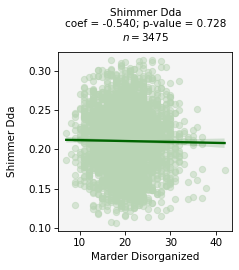

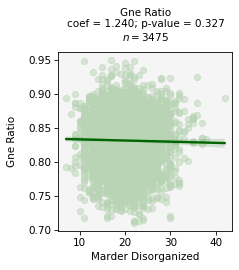

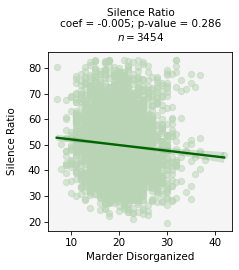

In [28]:
# Linear mixed effect model, with timepoint as a factor
for dhm in dhms:
    scatterplot(df_clean, 'marder_disorganized', [dhm, 'age', 'male', 'black'], 'Marder Disorganized', dhm.replace("_", " ").title(), None, 0.05, 'lme', dpi=200, filename=figure_dir+f"3.1.3_scatterplot_lme_marder-disorganized_{dhm}.png")
    scatterplot(df_clean, 'marder_disorganized', [dhm, 'age', 'male', 'black'], 'Marder Disorganized', dhm.replace("_", " ").title(), None, 1, 'lme', dpi=75)

##### 3.1.4 - Marder hostility

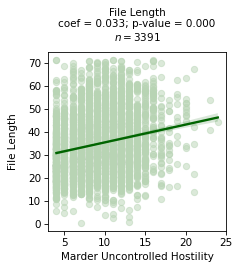

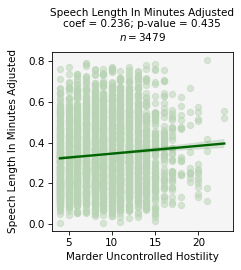

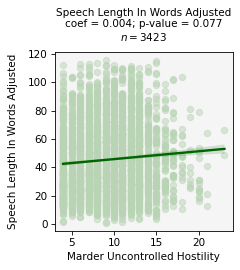

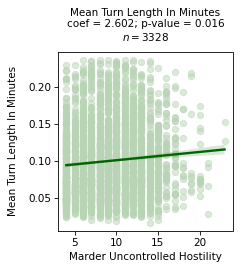

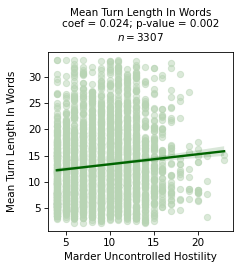

...

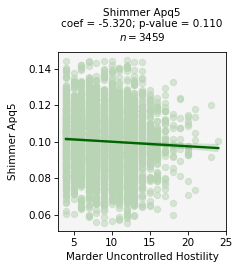

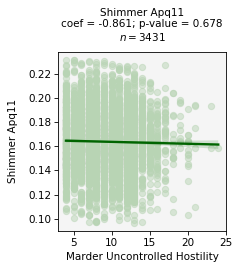

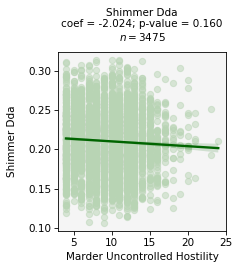

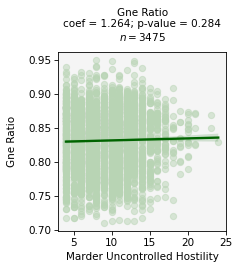

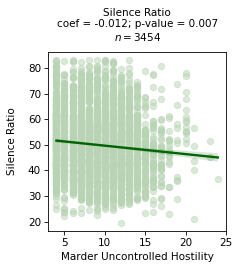

In [29]:
# Linear mixed effect model, with timepoint as a factor
for dhm in dhms:
    scatterplot(df_clean, 'marder_uncontrolled', [dhm, 'age', 'male', 'black'], 'Marder Uncontrolled Hostility', dhm.replace("_", " ").title(), None, 0.05, 'lme', dpi=200, filename=figure_dir+f"3.1.4_scatterplot_lme_marder-hostility_{dhm}.png")
    scatterplot(df_clean, 'marder_uncontrolled', [dhm, 'age', 'male', 'black'], 'Marder Uncontrolled Hostility', dhm.replace("_", " ").title(), None, 1, 'lme', dpi=75)

##### 3.1.5 - Marder anxiety/depression

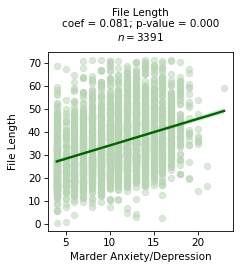

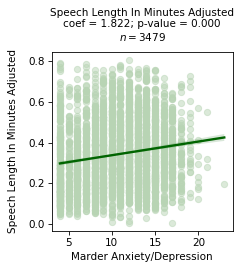

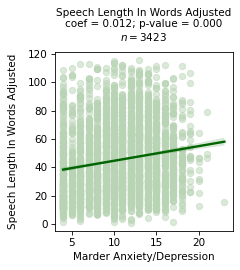

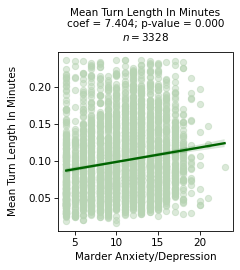

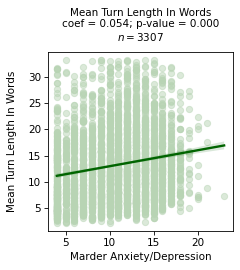

...

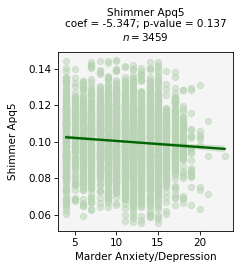

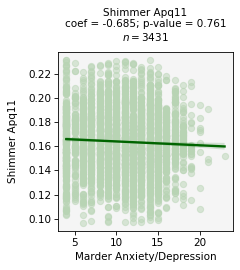

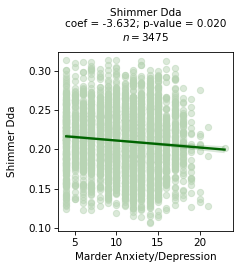

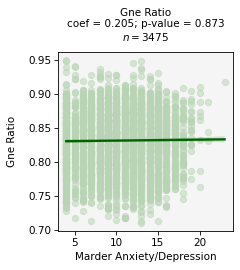

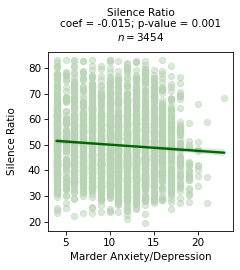

In [30]:
# Linear mixed effect model, with timepoint as a factor
for dhm in dhms:
    scatterplot(df_clean, 'marder_anxiety', [dhm, 'age', 'male', 'black'], 'Marder Anxiety/Depression', dhm.replace("_", " ").title(), None, 0.05, 'lme', dpi=200, filename=figure_dir+f"3.1.5_scatterplot_lme_marder-anxiety_{dhm}.png")
    scatterplot(df_clean, 'marder_anxiety', [dhm, 'age', 'male', 'black'], 'Marder Anxiety/Depression', dhm.replace("_", " ").title(), None, 1, 'lme', dpi=75)

#### 3.2 - Summary tables

In [31]:
summaries_marder = {
    'marder_positive': [], 'marder_negative': [], 'marder_disorganized': [], 'marder_uncontrolled': [], 'marder_anxiety': []
}

r_code = """
result <- lme_test(df_plot, dv, fefs, refs, FALSE, TRUE)
"""

df2 = df_clean.copy()
for dep_var in tqdm(summaries_marder.keys(), desc=f"Dependent Variables"):
    for dhm in tqdm(dhms, desc=f"DHMs ({dep_var})"):
        df_plot = df2.dropna(
            subset=['id', dep_var] + [dhm, 'age', 'male', 'black', 'visit']
        ).copy()

        # run model
        try:
            with localconverter(ro.default_converter + pandas2ri.converter):
                r_df_plot = ro.conversion.py2rpy(df_plot)

            # Assign the dataframe and variables to R
            ro.globalenv['df_plot'] = r_df_plot
            ro.globalenv['dv'] = dep_var
            ro.globalenv['fefs'] = ro.StrVector([dhm, 'age', 'male', 'black'])
            ro.globalenv['refs'] = ro.StrVector(['id', 'visit'])

            ro.r(r_code)
            result = ro.globalenv['result']
            result_dict = dict(zip([str(x) for x in result.names], list(result)))
            
            pval = result_dict['pval'][0]
            coef = result_dict['coef'][0]
            ci = result_dict['conf_int'][0]
            partial_r2 = result_dict['partial_r2'][0]
#             part_r2 = result_dict['part_r2'][0]
            partial_eta2 = result_dict['partial_eta2'][0]
        except:
            pval = 1
            coef = 1

        if pval < 0.05:
            res = []
            if coef > 0:
                res.append('+')
            else:
                res.append('-')

            res.append(f'{np.round(coef, 3)} ({np.round(ci[0], 3)}, {np.round(ci[1], 3)})')
            res.append(f'{np.round(partial_r2, 3)}')
#             res.append(f'{np.round(part_r2, 3)}')
            res.append(f'{np.round(partial_eta2, 3)}')

            summaries_marder[dep_var].append(res)
        else:
            summaries_marder[dep_var].append(['' for _ in range(5)])

DHMs (marder_positive):   0%|                            | 0/80 [00:00<?, ?it/s]R[write to console]: Computing profile confidence intervals ...


DHMs (marder_positive):   1%|▎                   | 1/80 [00:03<04:28,  3.40s/it]R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: Warning message:

R[write to console]: In checkConv(attr(opt, "derivs"), opt$par, ctrl = control$checkConv,  :
R[write to console]: 
 
R[write to console]:  Model failed to converge with max|grad| = 0.00408398 (tol = 0.002, component 1)


DHMs (marder_positive):   2%|▌                   | 2/80 [00:07<04:41,  3.61s/it]R[write to console]: Computing profile confidence intervals ...


DHMs (marder_positive):   4%|▊                   | 3/80 [00:11<04:58,  3.88s/it]R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: Warning message:

R[write to console]: In checkConv(attr(opt, "deri

In [32]:
summary_data = {
    'DHM': [item.replace('_', ' ').title() for item in dhms],
    'Marder Positive': [x[0] for x in summaries_marder['marder_positive']],
    'Marder Negative': [x[0] for x in summaries_marder['marder_negative']],
    'Disorganized thought': [x[0] for x in summaries_marder['marder_disorganized']],
    'Uncontrolled hostility': [x[0] for x in summaries_marder['marder_uncontrolled']],
    'Anxiety / depression': [x[0] for x in summaries_marder['marder_anxiety']],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Positive,Marder Negative,Disorganized thought,Uncontrolled hostility,Anxiety / depression
0,File Length,+,-,+,+,+
1,Speech Length In Minutes Adjusted,+,-,+,,+
2,Speech Length In Words Adjusted,+,-,+,,+
3,Mean Turn Length In Minutes,+,-,+,+,+
4,Mean Turn Length In Words,+,-,+,+,+
5,Speaker Percentage,+,-,+,,+
6,Words Per Minute,+,-,,+,+
7,Syllables Per Minute,+,-,,+,+
8,Word Pause Length Mean,-,+,,,-
9,Word Pause Variability,-,+,,,


In [33]:
summary_data = {
    'DHM': [item.replace('_', ' ').title() for item in dhms],
    'Marder Positive (direction)': [x[0] for x in summaries_marder['marder_positive']],
    'Marder Positive (statistics)': [f'partial R2: {x[2]}, partial eta2: {x[3]}' if x[0]!='' else '' for x in summaries_marder['marder_positive']],
    'Marder Negative (direction)': [x[0] for x in summaries_marder['marder_negative']],
    'Marder Negative (statistics)': [f'partial R2: {x[2]}, partial eta2: {x[3]}' if x[0]!='' else '' for x in summaries_marder['marder_negative']],
    'Disorganized thought (direction)': [x[0] for x in summaries_marder['marder_disorganized']],
    'Disorganized thought (statistics)': [f'partial R2: {x[2]}, partial eta2: {x[3]}' if x[0]!='' else '' for x in summaries_marder['marder_disorganized']],
    'Uncontrolled hostility (direction)': [x[0] for x in summaries_marder['marder_uncontrolled']],
    'Uncontrolled hostility (statistics)': [f'partial R2: {x[2]}, partial eta2: {x[3]}' if x[0]!='' else '' for x in summaries_marder['marder_uncontrolled']],
    'Anxiety / depression (direction)': [x[0] for x in summaries_marder['marder_anxiety']],
    'Anxiety / depression (statistics)': [f'partial R2: {x[2]}, partial eta2: {x[3]}' if x[0]!='' else '' for x in summaries_marder['marder_anxiety']],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Positive (direction),Marder Positive (statistics),Marder Negative (direction),Marder Negative (statistics),Disorganized thought (direction),Disorganized thought (statistics),Uncontrolled hostility (direction),Uncontrolled hostility (statistics),Anxiety / depression (direction),Anxiety / depression (statistics)
0,File Length,+,"partial R2: 0.061, partial eta2: 0.08",-,"partial R2: 0.006, partial eta2: 0.006",+,"partial R2: 0.011, partial eta2: 0.015",+,"partial R2: 0.014, partial eta2: 0.014",+,"partial R2: 0.076, partial eta2: 0.077"
1,Speech Length In Minutes Adjusted,+,"partial R2: 0.016, partial eta2: 0.027",-,"partial R2: 0.016, partial eta2: 0.026",+,"partial R2: 0.001, partial eta2: 0.002",,,+,"partial R2: 0.008, partial eta2: 0.01"
2,Speech Length In Words Adjusted,+,"partial R2: 0.019, partial eta2: 0.032",-,"partial R2: 0.025, partial eta2: 0.039",+,"partial R2: 0.001, partial eta2: 0.002",,,+,"partial R2: 0.008, partial eta2: 0.009"
3,Mean Turn Length In Minutes,+,"partial R2: 0.016, partial eta2: 0.029",-,"partial R2: 0.013, partial eta2: 0.02",+,"partial R2: 0.002, partial eta2: 0.005",+,"partial R2: 0.001, partial eta2: 0.002",+,"partial R2: 0.01, partial eta2: 0.012"
4,Mean Turn Length In Words,+,"partial R2: 0.016, partial eta2: 0.028",-,"partial R2: 0.023, partial eta2: 0.036",+,"partial R2: 0.001, partial eta2: 0.003",+,"partial R2: 0.002, partial eta2: 0.003",+,"partial R2: 0.011, partial eta2: 0.013"
5,Speaker Percentage,+,"partial R2: 0.021, partial eta2: 0.034",-,"partial R2: 0.027, partial eta2: 0.041",+,"partial R2: 0.001, partial eta2: 0.001",,,+,"partial R2: 0.008, partial eta2: 0.008"
6,Words Per Minute,+,"partial R2: 0.007, partial eta2: 0.009",-,"partial R2: 0.022, partial eta2: 0.029",,,+,"partial R2: 0.003, partial eta2: 0.004",+,"partial R2: 0.003, partial eta2: 0.003"
7,Syllables Per Minute,+,"partial R2: 0.006, partial eta2: 0.009",-,"partial R2: 0.019, partial eta2: 0.026",,,+,"partial R2: 0.003, partial eta2: 0.003",+,"partial R2: 0.004, partial eta2: 0.004"
8,Word Pause Length Mean,-,"partial R2: 0.006, partial eta2: 0.009",+,"partial R2: 0.02, partial eta2: 0.03",,,,,-,"partial R2: 0.002, partial eta2: 0.002"
9,Word Pause Variability,-,"partial R2: 0.003, partial eta2: 0.006",+,"partial R2: 0.015, partial eta2: 0.026",,,,,,


#### 3.3 - Marder Factor feature importances

In [34]:
df2 = df_clean.copy()
df2 = df2.dropna(
    subset=['id', 'marder_positive', 'marder_negative', 'marder_disorganized', 'marder_uncontrolled', 'marder_anxiety', 'age', 'male', 'white', 'black', 'visit'] + dhms
).copy()

with localconverter(ro.default_converter + pandas2ri.converter):
    r_df2 = ro.conversion.py2rpy(df2)
    
r_code = "result <- step_forward_selection(df_plot, dv, initial, candidates, random_effs)"

In [35]:
# Marder Positive
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'marder_positive'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_effs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_marder_positive = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [36]:
# Marder Negative
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'marder_negative'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_effs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_marder_negative = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [37]:
# Marder Disorganized
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'marder_disorganized'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_effs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_marder_disorganized = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [38]:
# Marder Uncontrolled
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'marder_uncontrolled'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_effs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_marder_uncontrolled = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [39]:
# Marder Anxiety
ro.globalenv['df2'] = r_df2
ro.globalenv['dv'] = 'marder_anxiety'
ro.globalenv['initial'] = ro.StrVector(['age', 'male', 'black'])
ro.globalenv['candidates'] = ro.StrVector(dhms[1:])
ro.globalenv['random_effs'] = ro.StrVector(['id', 'visit'])

ro.r(r_code)
result = ro.globalenv['result']
result_dict = dict(zip([str(x) for x in result.names], list(result)))

var_contributions_marder_anxiety = (result_dict['vars'], result_dict['stats'])

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: Computing profile confidence intervals ...

R[write to console]: In addition: 
R[write to console]: There were 50 or more warnings (use warnings() to see the first 50)
R[write to console]: 



In [40]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_marder_positive[0]],
    'Marder Positive (partial R^2)': [x[0] for x in var_contributions_marder_positive[1]],
    'Marder Positive (partial eta^2)': [x[1] for x in var_contributions_marder_positive[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Positive (partial R^2),Marder Positive (partial eta^2)
0,Lexical Richness,0.043179,0.071731
1,Speech Length In Minutes Adjusted,0.003818,0.004812


In [41]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_marder_negative[0]],
    'Marder Negative (partial R^2)': [x[0] for x in var_contributions_marder_negative[1]],
    'Marder Negative (partial eta^2)': [x[1] for x in var_contributions_marder_negative[1]],
}


df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Negative (partial R^2),Marder Negative (partial eta^2)
0,Speaker Percentage,0.026410,0.039925
1,Mean Pre Turn Pause,0.027047,0.018893
2,Negative Sentiment,0.007599,0.009514
3,Words Per Minute,0.007477,0.007813


In [42]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_marder_disorganized[0]],
    'Marder Disorganized (partial R^2)': [x[0] for x in var_contributions_marder_disorganized[1]],
    'Marder Disorganized (partial eta^2)': [x[1] for x in var_contributions_marder_disorganized[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Disorganized (partial R^2),Marder Disorganized (partial eta^2)
0,Lexical Richness,0.004815,0.012490
1,Word Pause Length Mean,0.006060,0.007911
2,Positive Sentiment,0.002019,0.004734
3,Word Coherence Variability 3 Var,0.000987,0.006396
4,Speech Length In Minutes Adjusted,0.004995,0.005547


In [43]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_marder_uncontrolled[0]],
    'Marder Uncontrolled (partial R^2)': [x[0] for x in var_contributions_marder_uncontrolled[1]],
    'Marder Uncontrolled (partial eta^2)': [x[1] for x in var_contributions_marder_uncontrolled[1]],
}


df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Uncontrolled (partial R^2),Marder Uncontrolled (partial eta^2)
0,Negative Sentiment,0.007832,0.009734
1,Lexical Richness,0.007365,0.007279
2,Speech Length In Minutes Adjusted,0.005034,0.004674


In [44]:
summary_data = {
    'DHM': [x.replace('_', ' ').title() for x in var_contributions_marder_anxiety[0]],
    'Marder Anxiety (partial R^2)': [x[0] for x in var_contributions_marder_anxiety[1]],
    'Marder Anxiety (partial eta^2)': [x[1] for x in var_contributions_marder_anxiety[1]],
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Marder Anxiety (partial R^2),Marder Anxiety (partial eta^2)
0,Lexical Richness,0.038519,0.049375
1,Negative Sentiment,0.017842,0.021224
2,Speaker Percentage,0.019860,0.017692
3,First Person Percentage,0.009882,0.005416
4,First Person Sentiment Negative,0.007337,0.008966
5,Word Repeat Percentage,0.004625,0.005323
